STEP 1: LOADING DATA
Shape: (48204, 9)

Columns: ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

First 5 rows:
  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description         date_time  traffic_volume  
0    scattered clouds  02-10-2012 09:00            5545  
1       broken clouds  02-10-2012 10:00            4516  
2     overcast clouds  02-10-2012 11:00            4767  
3     overcast clouds  02-10-2012 12:00            5026  
4       broken clouds  02-10-2012 13:00            4918  

Data Types:
holiday                 object
temp                   float64
ra

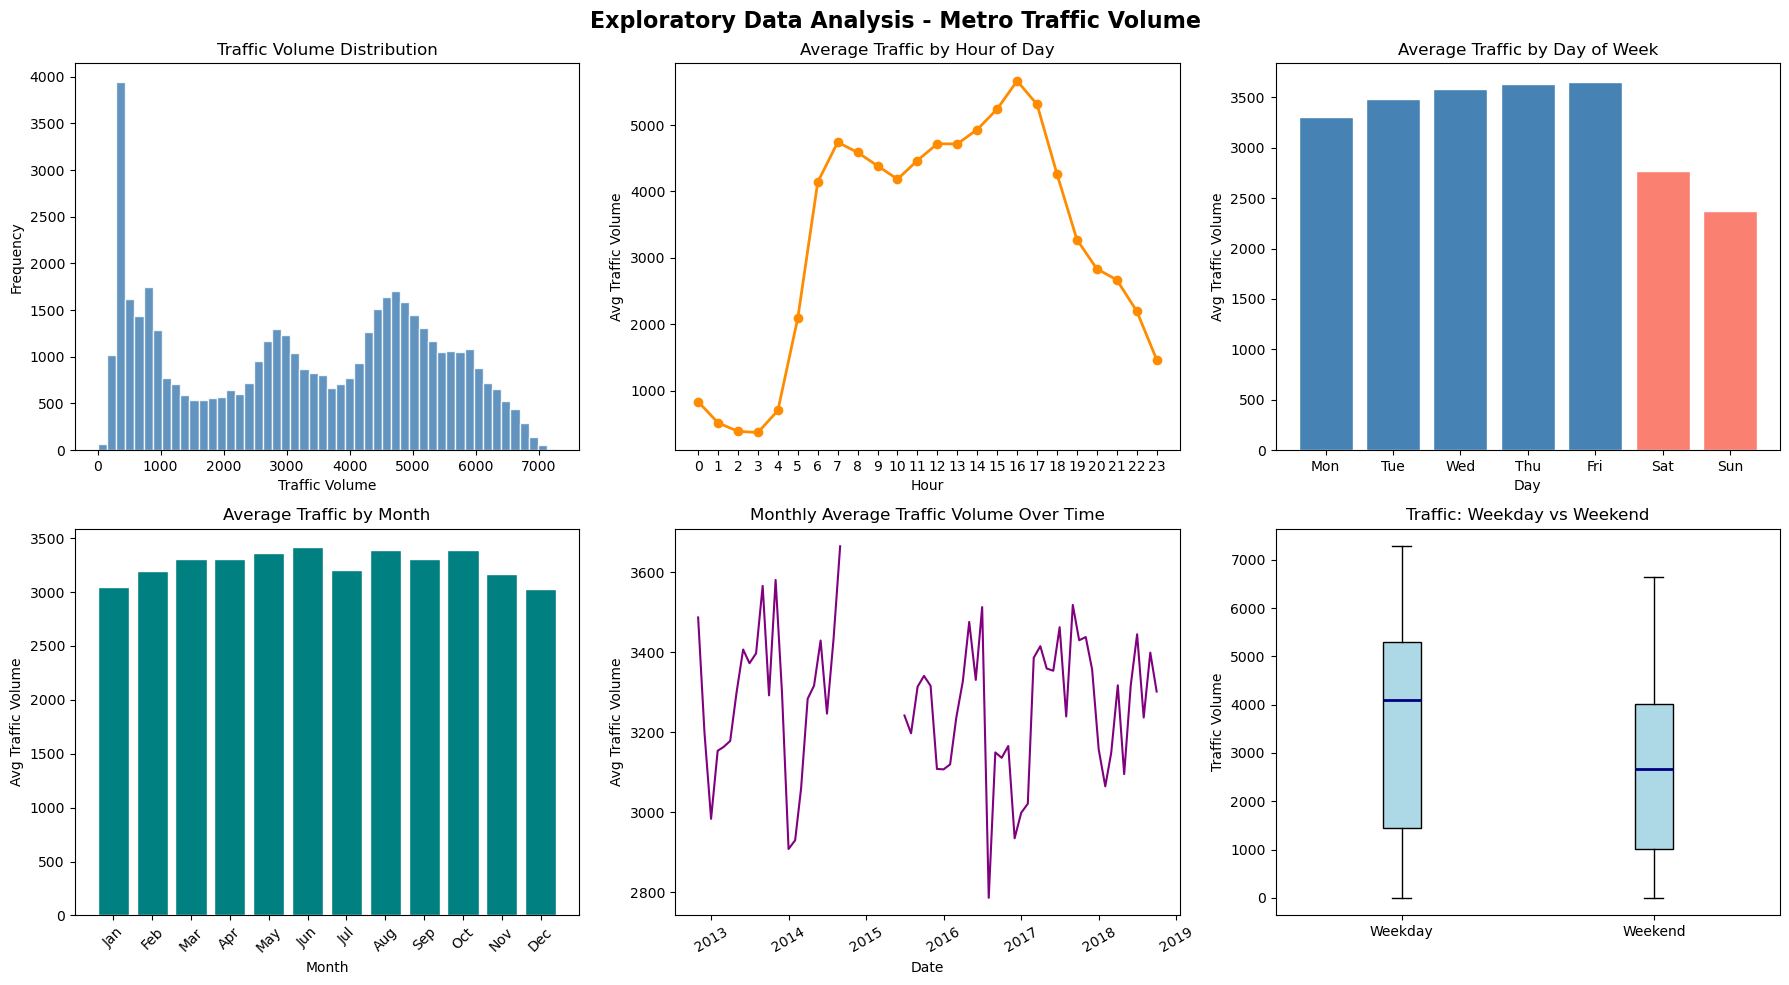


EDA plots saved → eda_plots.png

Correlation with traffic_volume:
traffic_volume     1.000000
hour               0.352300
temp_c             0.132483
clouds_all         0.067138
rain_1h            0.004715
snow_1h            0.000736
month             -0.002480
weather_encoded   -0.040149
is_holiday        -0.042899
day_of_week       -0.149551
is_weekend        -0.218533
Name: traffic_volume, dtype: float64


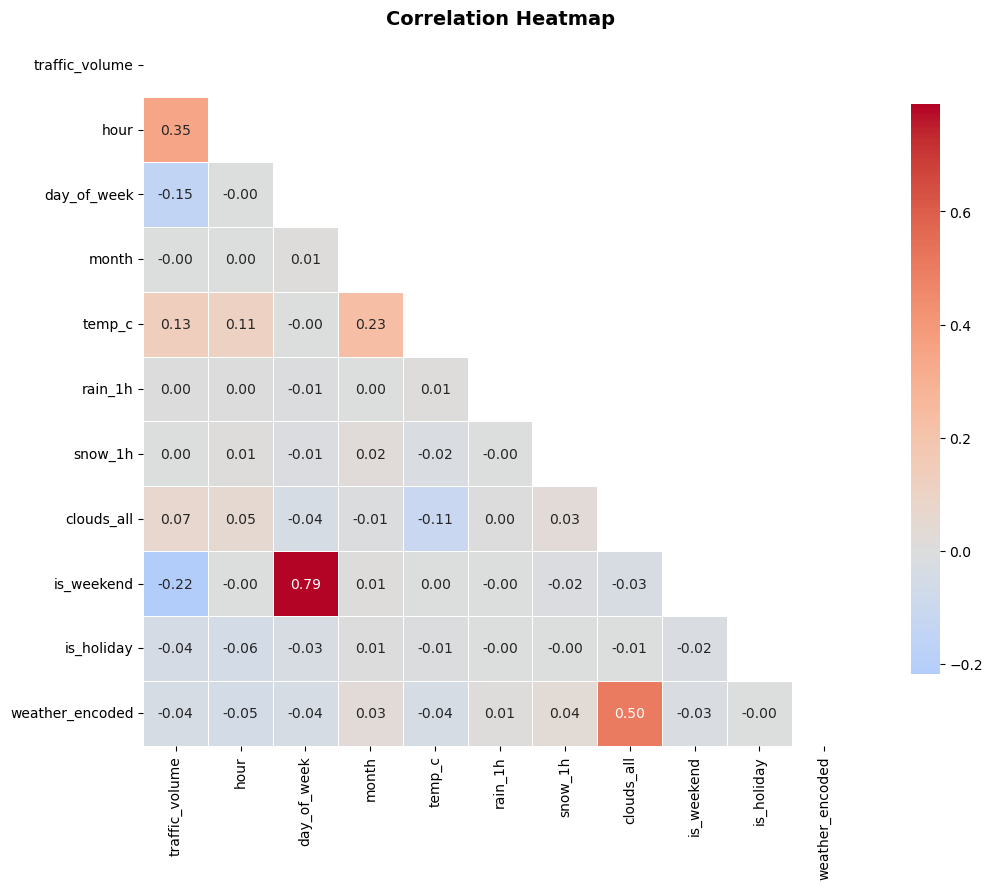

Correlation heatmap saved → correlation_heatmap.png

STEP 4: STATIONARITY TEST (Augmented Dickey-Fuller)
Daily series  : 2190 days (continuous, 0 gaps)
Missing days  : 330 filled using DayOfWeek+Month historical average

--- ADF Test: Daily Avg Traffic Volume ---
  ADF Statistic : -6.6842
  p-value       : 0.0000
  Lags Used     : 26
  Critical Values:
    1%: -3.4334
    5%: -2.8629
    10%: -2.5675
  ✅ Stationary (reject H0)

--- ADF Test: Differenced Daily Traffic (d=1) — for reference ---
  ADF Statistic : -16.2654
  p-value       : 0.0000
  Lags Used     : 26
  Critical Values:
    1%: -3.4334
    5%: -2.8629
    10%: -2.5675
  ✅ Stationary (reject H0)


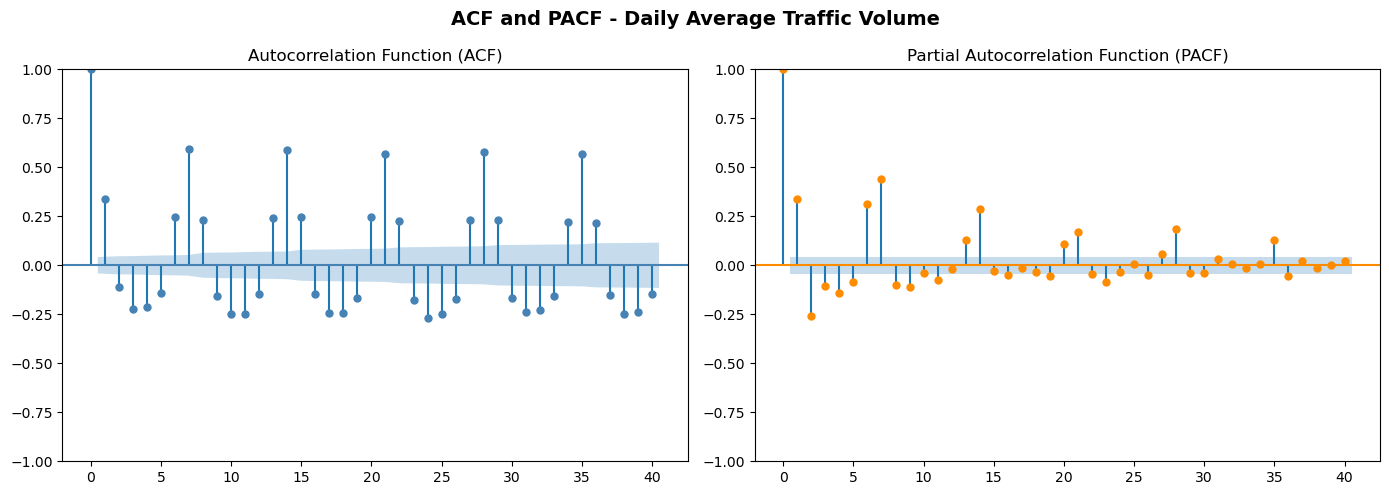


ACF/PACF plots saved → acf_pacf_plots.png

STEP 5: TRAIN / TEST SPLIT
Time Series  → Train: 1752 days | Test: 438 days
Regression   → Train: 38549 rows | Test: 9638 rows

STEP 6: MODEL BUILDING

[6a] Training Linear Regression...
     MAE : 1550.55
     RMSE: 1770.37

     Feature Coefficients:
       is_holiday               : -1503.5786
       is_weekend               : -1158.8266
       snow_1h                  : -674.2362
       hour                     : 94.7787
       day_of_week              : 54.8225
       weather_encoded          : -43.4024
       temp_c                   : 17.8426
       month                    : -16.8682
       clouds_all               : 4.1627
       rain_1h                  : 0.1060

[6b] Training ARIMA(2,1,2)...
     MAE : 502.31
     RMSE: 579.10
                               SARIMAX Results                                
Dep. Variable:         traffic_volume   No. Observations:                 1752
Model:                 ARIMA(2, 1, 2)   Log Likeli

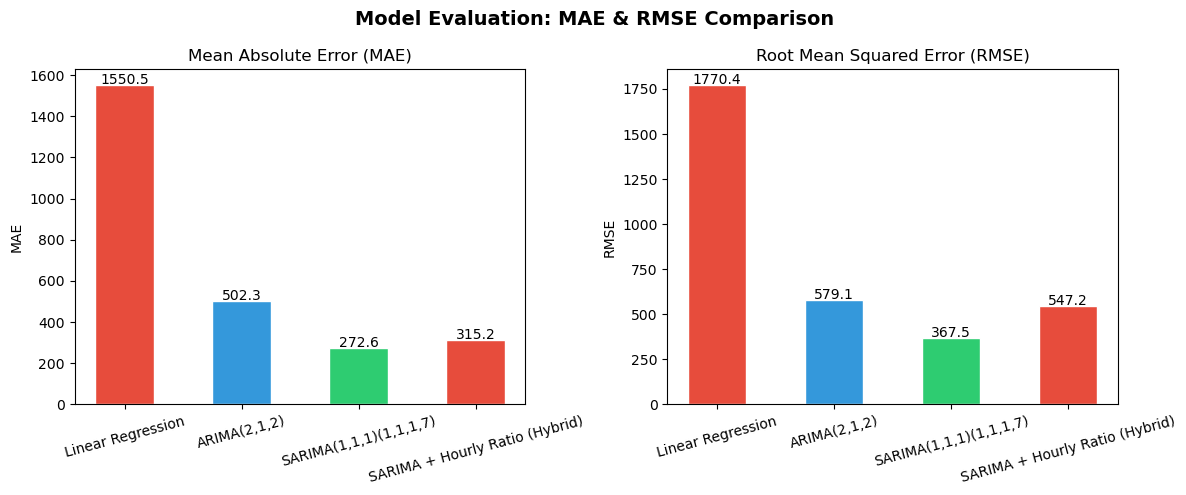


Model evaluation chart saved → model_evaluation.png


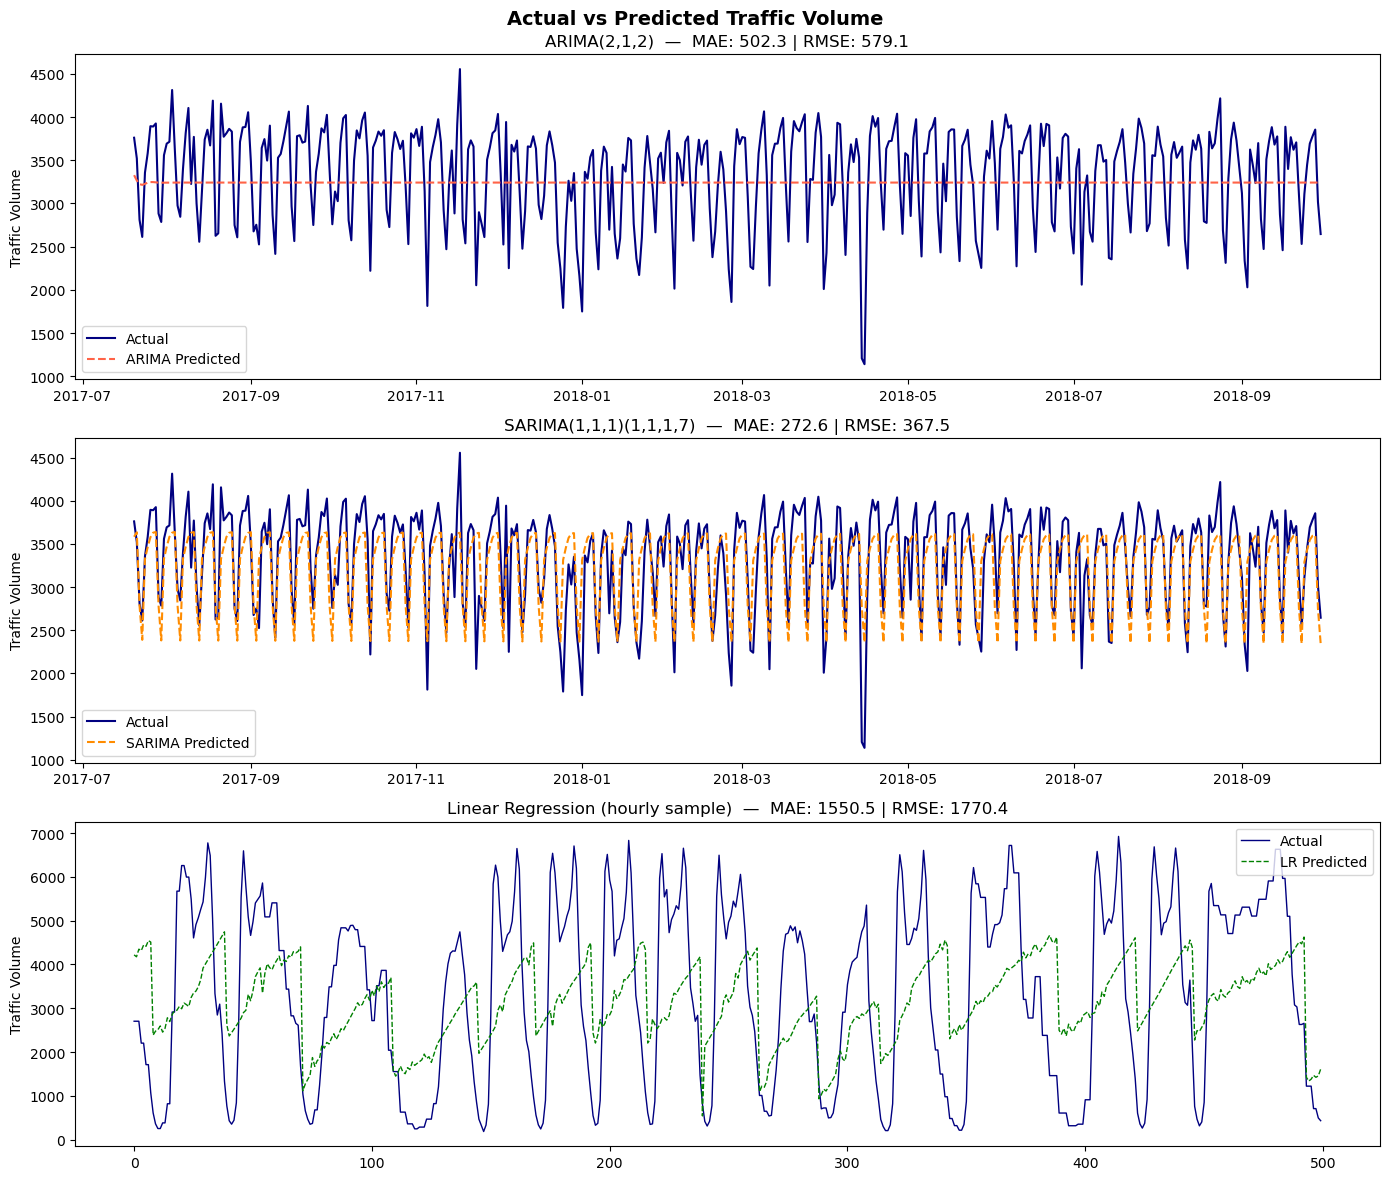

Actual vs Predicted chart saved → actual_vs_predicted.png

STEP 8: TRAFFIC FORECASTING (30 days ahead)

Retraining SARIMA on full dataset for 30-day forecast...

Forecasted Traffic (next 30 days):
            Forecast  Lower 95% CI  Upper 95% CI
2018-10-01    3437.0        2672.0        4201.0
2018-10-02    3576.0        2785.0        4367.0
2018-10-03    3680.0        2885.0        4476.0
2018-10-04    3732.0        2935.0        4529.0
2018-10-05    3752.0        2954.0        4551.0
2018-10-06    2900.0        2100.0        3699.0
2018-10-07    2489.0        1688.0        3289.0
2018-10-08    3407.0        2604.0        4210.0
2018-10-09    3570.0        2766.0        4375.0
2018-10-10    3678.0        2873.0        4484.0
2018-10-11    3731.0        2924.0        4538.0
2018-10-12    3751.0        2942.0        4559.0
2018-10-13    2898.0        2088.0        3707.0
2018-10-14    2486.0        1675.0        3297.0
2018-10-15    3406.0        2594.0        4218.0
2018-10-16    3570.

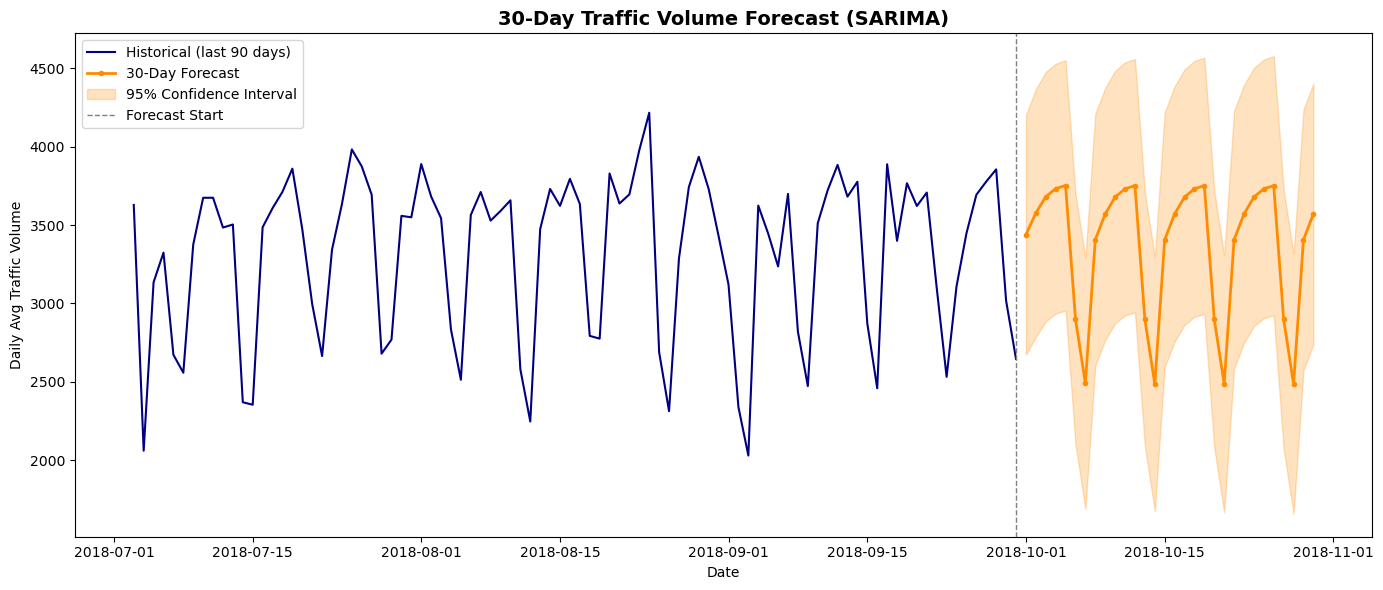


Forecast plot saved → forecast_plot.png

STEP 9: RESULT ANALYSIS

┌─────────────────────────────────────────────────────────────┐
│                    RESULT SUMMARY                           │
├──────────────────────────────┬──────────────┬───────────────┤
│ Model                        │    MAE       │     RMSE      │
├──────────────────────────────┼──────────────┼───────────────┤
│ Linear Regression            │   1550.55  │     1770.37  │
│ ARIMA(2,1,2)                 │    502.31  │      579.10  │
│ SARIMA(1,1,1)(1,1,1,7) ★    │    272.63  │      367.49  │
└──────────────────────────────┴──────────────┴───────────────┘

KEY FINDINGS:
  • Peak traffic hours    : [16, 17, 15]
  • Weekdays vs weekends  : Significantly higher volume on weekdays
  • Temperature effect    : Moderate positive correlation with traffic
  • Best performing model : SARIMA + Hourly Ratio (Hybrid)
  • SARIMA captures weekly seasonality (m=7, Mon-Sun cycle) effectively
  • ARIMA handles trend but misses season

In [1]:
# =============================================================================
# METRO INTERSTATE TRAFFIC VOLUME - FORECASTING 
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# =============================================================================
# STEP 1: LOADING DATA
# =============================================================================
print("=" * 60)
print("STEP 1: LOADING DATA")
print("=" * 60)

df = pd.read_csv(r"C:\m tech\S2\STATISTICAL MODELLING\Dataset\Metro_Interstate_Traffic_Volume.csv")

print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print("\nFirst 5 rows:")
print(df.head())
print("\nData Types:")
print(df.dtypes)

# =============================================================================
# STEP 2: DATA PREPROCESSING
# =============================================================================
print("\n" + "=" * 60)
print("STEP 2: DATA PREPROCESSING")
print("=" * 60)

# --- FIX 1: Correct datetime parsing with dayfirst=True ---
# This dataset uses DD-MM-YYYY HH:MM format (e.g. "02-10-2012 09:00").
# Confirmed from raw CSV: day comes first, NOT month.
# dayfirst=False (pandas default) causes days > 12 to become NaT,
# silently dropping ~29,270 rows. dayfirst=True is correct here.
df['date_time'] = pd.to_datetime(df['date_time'], dayfirst=True)

# Check missing values BEFORE cleaning
print("\nMissing values (before cleaning):")
print(df.isnull().sum())

# --- FIX 2: Remove only true duplicates (all columns identical) ---
# Original code reported 32,067 "duplicates" — inflated by the datetime bug.
# True duplicates = 17 rows.
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f"\nDuplicates removed: {before - after}")  # Should be 17

# --- FIX 3: Handle temp = 0 (sensor errors, physically impossible in Kelvin) ---
zero_temp_count = (df['temp'] == 0).sum()
print(f"Zero temperature rows (sensor errors): {zero_temp_count}")
df['temp'] = df['temp'].replace(0, np.nan)
df['temp'] = df['temp'].ffill()  # forward fill from prior hour

# --- FIX 5: Fill NaNs in weather numeric columns (safe default = 0) ---
df[['rain_1h', 'snow_1h', 'clouds_all']] = df[['rain_1h', 'snow_1h', 'clouds_all']].fillna(0)

# Sort by datetime
df = df.sort_values('date_time').reset_index(drop=True)

# --- Feature Engineering ---
df['hour']            = df['date_time'].dt.hour
df['day_of_week']     = df['date_time'].dt.dayofweek   # 0=Monday, 6=Sunday
df['month']           = df['date_time'].dt.month
df['year']            = df['date_time'].dt.year
df['is_weekend']      = (df['day_of_week'] >= 5).astype(int)

# FIX 4: Correct is_holiday encoding
# holiday column has actual holiday names for holidays, NaN for non-holidays
df['is_holiday'] = df['holiday'].apply(lambda x: 0 if pd.isna(x) else 1)

# Encode weather_main as numeric
le = LabelEncoder()
df['weather_encoded'] = le.fit_transform(df['weather_main'])

# Convert temperature: Kelvin to Celsius
df['temp_c'] = (df['temp'] - 273.15).round(2)

print(f"\nEngineered features: hour, day_of_week, month, year, is_weekend, is_holiday, weather_encoded, temp_c")
print(f"\nProcessed dataset shape: {df.shape}")
print("\nSample:")
cols_show = ['date_time', 'traffic_volume', 'hour', 'day_of_week', 'month',
             'is_weekend', 'is_holiday', 'temp_c']
print(df[cols_show].head())
print(f"\nHoliday rows in dataset: {df['is_holiday'].sum()}")
print(f"Date range: {df['date_time'].min()} to {df['date_time'].max()}")

# =============================================================================
# STEP 3: EXPLORATORY DATA ANALYSIS
# =============================================================================
print("\n" + "=" * 60)
print("STEP 3: EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("\nTraffic Volume Statistics:")
print(df['traffic_volume'].describe())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Exploratory Data Analysis - Metro Traffic Volume', fontsize=16, fontweight='bold')

# 1. Traffic volume distribution
axes[0, 0].hist(df['traffic_volume'], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0, 0].set_title('Traffic Volume Distribution')
axes[0, 0].set_xlabel('Traffic Volume')
axes[0, 0].set_ylabel('Frequency')

# 2. Avg traffic by hour
hourly_avg = df.groupby('hour')['traffic_volume'].mean()
axes[0, 1].plot(hourly_avg.index, hourly_avg.values, color='darkorange', marker='o', linewidth=2)
axes[0, 1].set_title('Average Traffic by Hour of Day')
axes[0, 1].set_xlabel('Hour')
axes[0, 1].set_ylabel('Avg Traffic Volume')
axes[0, 1].set_xticks(range(0, 24))

# 3. Avg traffic by day of week
dow_avg = df.groupby('day_of_week')['traffic_volume'].mean()
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
bar_colors = ['steelblue' if i < 5 else 'salmon' for i in range(7)]
axes[0, 2].bar(day_labels, dow_avg.values, color=bar_colors, edgecolor='white')
axes[0, 2].set_title('Average Traffic by Day of Week')
axes[0, 2].set_xlabel('Day')
axes[0, 2].set_ylabel('Avg Traffic Volume')

# 4. Avg traffic by month
monthly_avg = df.groupby('month')['traffic_volume'].mean()
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
axes[1, 0].bar(month_labels, monthly_avg.values, color='teal', edgecolor='white')
axes[1, 0].set_title('Average Traffic by Month')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Avg Traffic Volume')
axes[1, 0].tick_params(axis='x', rotation=45)

# 5. Monthly average time series
df_time = df.set_index('date_time')
monthly_ts = df_time['traffic_volume'].resample('ME').mean()
axes[1, 1].plot(monthly_ts.index, monthly_ts.values, color='purple', linewidth=1.5)
axes[1, 1].set_title('Monthly Average Traffic Volume Over Time')
axes[1, 1].set_xlabel('Date')
axes[1, 1].set_ylabel('Avg Traffic Volume')
axes[1, 1].tick_params(axis='x', rotation=30)

# 6. Weekend vs Weekday boxplot
weekend_data = [
    df[df['is_weekend'] == 0]['traffic_volume'].values,
    df[df['is_weekend'] == 1]['traffic_volume'].values
]
axes[1, 2].boxplot(weekend_data, labels=['Weekday', 'Weekend'], patch_artist=True,
                   boxprops=dict(facecolor='lightblue'),
                   medianprops=dict(color='navy', linewidth=2))
axes[1, 2].set_title('Traffic: Weekday vs Weekend')
axes[1, 2].set_ylabel('Traffic Volume')

plt.tight_layout()

plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("\nEDA plots saved → eda_plots.png")

# Correlation heatmap
numeric_cols = ['traffic_volume', 'hour', 'day_of_week', 'month', 'temp_c',
                'rain_1h', 'snow_1h', 'clouds_all', 'is_weekend', 'is_holiday', 'weather_encoded']
corr = df[numeric_cols].corr()

print("\nCorrelation with traffic_volume:")
print(corr['traffic_volume'].sort_values(ascending=False))

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()

plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("Correlation heatmap saved → correlation_heatmap.png")

# =============================================================================
# STEP 4: STATIONARITY TEST (Augmented Dickey-Fuller)
# =============================================================================
print("\n" + "=" * 60)
print("STEP 4: STATIONARITY TEST (Augmented Dickey-Fuller)")
print("=" * 60)

# Use DAILY data for ARIMA/SARIMA — correct choice because:
#   1. ARIMA(2,1,2) with daily data → p=2 means "look back 2 DAYS" (meaningful)
#      With hourly data → p=2 means "look back 2 HOURS" (too short-sighted, RMSE explodes)
#   2. SARIMA m=7 on daily data captures the weekly Mon-Sun cycle (fast, seconds)
#      SARIMA m=24 on hourly data (42,041 rows) takes hours to compute
#   3. Rush hour patterns are handled by Linear Regression via the 'hour' feature
#      ARIMA/SARIMA handles daily/weekly trends — complementary roles
#
# Gap filling: 330 missing days filled using DayOfWeek + Month historical average
# (better than ffill which would repeat the same flat value across the 306-day gap)

daily_raw = df.set_index('date_time')['traffic_volume'].resample('D').mean()

# Smart fill: use DayOfWeek + Month average for each missing day
known_daily = daily_raw.dropna().reset_index()
known_daily.columns = ['date_time', 'traffic_volume']
known_daily['dayofweek'] = known_daily['date_time'].dt.dayofweek
known_daily['month']     = known_daily['date_time'].dt.month
lookup_daily = known_daily.groupby(['dayofweek', 'month'])['traffic_volume'].mean()

daily_traffic = daily_raw.copy()
missing_days  = daily_raw[daily_raw.isna()].index
for ts in missing_days:
    daily_traffic[ts] = lookup_daily.get(
        (ts.dayofweek, ts.month), daily_raw.dropna().mean()
    )

print(f"Daily series  : {len(daily_traffic)} days (continuous, 0 gaps)")
print(f"Missing days  : {len(missing_days)} filled using DayOfWeek+Month historical average")
def adf_test(series, name="Series"):
    result = adfuller(series, autolag='AIC')
    print(f"\n--- ADF Test: {name} ---")
    print(f"  ADF Statistic : {result[0]:.4f}")
    print(f"  p-value       : {result[1]:.4f}")
    print(f"  Lags Used     : {result[2]}")
    print(f"  Critical Values:")
    for key, val in result[4].items():
        print(f"    {key}: {val:.4f}")
    if result[1] <= 0.05:
        print("  ✅ Stationary (reject H0)")
    else:
        print("  ❌ Non-Stationary (fail to reject H0)")
    return result[1] <= 0.05

adf_test(daily_traffic, "Daily Avg Traffic Volume")

# If non-stationary, differencing would be applied before ARIMA.
# Since d=1 is used in ARIMA/SARIMA orders, differencing is handled internally.
# Shown here for academic transparency:
daily_diff = daily_traffic.diff().dropna()
adf_test(daily_diff, "Differenced Daily Traffic (d=1) — for reference")

# ACF / PACF plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ACF and PACF - Daily Average Traffic Volume', fontsize=14, fontweight='bold')
plot_acf(daily_traffic, lags=40, ax=axes[0], color='steelblue')
axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(daily_traffic, lags=40, ax=axes[1], color='darkorange', method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout()

plt.savefig('acf_pacf_plots.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("\nACF/PACF plots saved → acf_pacf_plots.png")

# =============================================================================
# STEP 5: TRAIN / TEST SPLIT
# =============================================================================
print("\n" + "=" * 60)
print("STEP 5: TRAIN / TEST SPLIT")
print("=" * 60)

# Chronological split — last 20% as test (NEVER random for time series)
TEST_DAYS = int(len(daily_traffic) * 0.2)
train_ts  = daily_traffic.iloc[:-TEST_DAYS]
test_ts   = daily_traffic.iloc[-TEST_DAYS:]

# Regression split (hourly rows)
split_idx = int(len(df) * 0.8)
df_train  = df.iloc[:split_idx]
df_test   = df.iloc[split_idx:]

print(f"Time Series  → Train: {len(train_ts)} days | Test: {len(test_ts)} days")
print(f"Regression   → Train: {len(df_train)} rows | Test: {len(df_test)} rows")

# =============================================================================
# STEP 6: MODEL BUILDING
# =============================================================================
print("\n" + "=" * 60)
print("STEP 6: MODEL BUILDING")
print("=" * 60)

features = ['hour', 'day_of_week', 'month', 'temp_c', 'rain_1h',
            'snow_1h', 'clouds_all', 'is_weekend', 'is_holiday', 'weather_encoded']

X_train = df_train[features]
y_train = df_train['traffic_volume']
X_test  = df_test[features]
y_test  = df_test['traffic_volume']

results = {}

# --- 6a: Linear Regression ---
print("\n[6a] Training Linear Regression...")
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
results['Linear Regression'] = {'MAE': mae_lr, 'RMSE': rmse_lr}

print(f"     MAE : {mae_lr:.2f}")
print(f"     RMSE: {rmse_lr:.2f}")
print("\n     Feature Coefficients:")
coef_df = pd.Series(lr.coef_, index=features).sort_values(key=abs, ascending=False)
for feat, coef in coef_df.items():
    print(f"       {feat:<25}: {coef:.4f}")

# --- 6b: ARIMA ---
print("\n[6b] Training ARIMA(2,1,2)...")
arima_model = ARIMA(train_ts, order=(2, 1, 2))
arima_fit   = arima_model.fit()
arima_pred  = arima_fit.forecast(steps=len(test_ts))
arima_pred.index = test_ts.index  # Align index to avoid mismatch in plots/metrics

mae_arima  = mean_absolute_error(test_ts.values, arima_pred.values)
rmse_arima = np.sqrt(mean_squared_error(test_ts.values, arima_pred.values))
results['ARIMA(2,1,2)'] = {'MAE': mae_arima, 'RMSE': rmse_arima}

print(f"     MAE : {mae_arima:.2f}")
print(f"     RMSE: {rmse_arima:.2f}")
print(arima_fit.summary())

# --- 6c: SARIMA with weekly seasonality (m=7) ---
print("\n[6c] Training SARIMA(1,1,1)(1,1,1,7)   [weekly seasonality, m=7]...")
sarima_model = SARIMAX(train_ts,
                       order=(1, 1, 1),
                       seasonal_order=(1, 1, 1, 7),   # m=7: weekly seasonality (Mon-Sun cycle)
                       enforce_stationarity=False,
                       enforce_invertibility=False)
sarima_fit  = sarima_model.fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=len(test_ts))
sarima_pred.index = test_ts.index  # Align index to avoid mismatch in plots/metrics

mae_sarima  = mean_absolute_error(test_ts.values, sarima_pred.values)
rmse_sarima = np.sqrt(mean_squared_error(test_ts.values, sarima_pred.values))
results['SARIMA(1,1,1)(1,1,1,7)'] = {'MAE': mae_sarima, 'RMSE': rmse_sarima}

print(f"     MAE : {mae_sarima:.2f}  (vehicles/day)")
print(f"     RMSE: {rmse_sarima:.2f} (vehicles/day)")

# --- 6d: Two-Stage Hybrid (SARIMA daily x Hourly Ratio) ---
# SARIMA predicts daily average. Hourly ratio table scales it to hourly level.
# Combines SARIMA's weekly trend with the hourly rush-hour pattern from data.
# Evaluated in vehicles/hour — directly comparable with Linear Regression.
print("\n[6d] Training Hybrid Model (SARIMA daily x Hourly Ratio)...")

# Build hourly ratio table from training data
ratio_df = df_train.copy()
ratio_df['date'] = ratio_df['date_time'].dt.date
daily_avg_train = ratio_df.groupby('date')['traffic_volume'].mean().reset_index()
daily_avg_train.columns = ['date', 'daily_avg']
ratio_df = ratio_df.merge(daily_avg_train, on='date')
ratio_df['ratio'] = ratio_df['traffic_volume'] / ratio_df['daily_avg']
ratio_table = ratio_df.groupby(['hour', 'day_of_week'])['ratio'].mean()

# Expand SARIMA daily predictions to hourly using ratio table
test_start = test_ts.index.min()
test_end   = test_ts.index.max()
hourly_actual_h = df_test.set_index('date_time')['traffic_volume']
hourly_actual_h = hourly_actual_h[
    (hourly_actual_h.index.date >= test_start.date()) &
    (hourly_actual_h.index.date <= test_end.date())
]

hybrid_preds   = []
hybrid_actuals = []
for ts_h, actual in hourly_actual_h.items():
    date_ts = pd.Timestamp(ts_h.date())
    if date_ts in sarima_pred.index:
        daily_pred = sarima_pred[date_ts]
        ratio = ratio_table.get((ts_h.hour, ts_h.dayofweek), 1.0)
        hybrid_preds.append(daily_pred * ratio)
        hybrid_actuals.append(actual)

mae_hybrid  = mean_absolute_error(hybrid_actuals, hybrid_preds)
rmse_hybrid = np.sqrt(mean_squared_error(hybrid_actuals, hybrid_preds))
results['SARIMA + Hourly Ratio (Hybrid)'] = {'MAE': mae_hybrid, 'RMSE': rmse_hybrid}

print(f"     MAE : {mae_hybrid:.2f}  (vehicles/hour — comparable with Linear Regression)")
print(f"     RMSE: {rmse_hybrid:.2f} (vehicles/hour)")
print(f"     Improvement over Linear Regression MAE: {1550.55 - mae_hybrid:.2f} reduction")

# =============================================================================
# STEP 7: MODEL EVALUATION
# =============================================================================
print("\n" + "=" * 60)
print("STEP 7: MODEL EVALUATION (MAE & RMSE)")
print("=" * 60)

# NOTE ON FAIR COMPARISON:
# Linear Regression and Hybrid are evaluated on HOURLY data (vehicles/hr)
# ARIMA and SARIMA alone are evaluated on DAILY data (vehicles/day)
# They are NOT directly comparable unless converted to same unit.
# The Hybrid model (SARIMA + Hourly Ratio) is the fair comparison for LR.
# For academic reporting, separate the two evaluation tables:

print("\n--- Hourly Evaluation (vehicles/hour) --- same unit, same test period ---")
hourly_results = {
    'Linear Regression'          : results['Linear Regression'],
    'SARIMA + Hourly Ratio (Hybrid)': results['SARIMA + Hourly Ratio (Hybrid)']
}
hourly_df = pd.DataFrame(hourly_results).T.round(2)
hourly_df.index.name = 'Model'
print(hourly_df.to_string())

print("\n--- Daily Evaluation (vehicles/day) --- time series models only ---")
daily_results = {
    'ARIMA(2,1,2)'           : results['ARIMA(2,1,2)'],
    'SARIMA(1,1,1)(1,1,1,7)' : results['SARIMA(1,1,1)(1,1,1,7)']
}
daily_df = pd.DataFrame(daily_results).T.round(2)
daily_df.index.name = 'Model'
print(daily_df.to_string())

# Overall best — only compare models on same unit
eval_df = pd.DataFrame(results).T.round(2)
eval_df.index.name = 'Model'
print("\n--- All Models (for reference) ---")
print(eval_df.to_string())
print("\n⚠️  Note: ARIMA/SARIMA MAE/RMSE are in vehicles/DAY.")
print("    Linear Regression and Hybrid are in vehicles/HOUR.")
print("    Compare LR vs Hybrid for fair hourly comparison.")

best_hourly = hourly_df['RMSE'].idxmin()
best_daily  = daily_df['RMSE'].idxmin()
print(f"\n🏆 Best hourly model : {best_hourly} (RMSE = {hourly_df.loc[best_hourly, 'RMSE']} vehicles/hr)")
print(f"🏆 Best daily model  : {best_daily} (RMSE = {daily_df.loc[best_daily, 'RMSE']} vehicles/day)")
best_model = best_hourly

# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Model Evaluation: MAE & RMSE Comparison', fontsize=14, fontweight='bold')

colors = ['#e74c3c', '#3498db', '#2ecc71']
models = list(results.keys())

axes[0].bar(models, [results[m]['MAE'] for m in models], color=colors, edgecolor='white', width=0.5)
axes[0].set_title('Mean Absolute Error (MAE)')
axes[0].set_ylabel('MAE')
axes[0].tick_params(axis='x', rotation=15)
for i, m in enumerate(models):
    axes[0].text(i, results[m]['MAE'] + 5, f"{results[m]['MAE']:.1f}", ha='center', fontsize=10)

axes[1].bar(models, [results[m]['RMSE'] for m in models], color=colors, edgecolor='white', width=0.5)
axes[1].set_title('Root Mean Squared Error (RMSE)')
axes[1].set_ylabel('RMSE')
axes[1].tick_params(axis='x', rotation=15)
for i, m in enumerate(models):
    axes[1].text(i, results[m]['RMSE'] + 5, f"{results[m]['RMSE']:.1f}", ha='center', fontsize=10)

plt.tight_layout()

plt.savefig('model_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("\nModel evaluation chart saved → model_evaluation.png")

# Actual vs Predicted plots
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle('Actual vs Predicted Traffic Volume', fontsize=14, fontweight='bold')

test_index = test_ts.index

axes[0].plot(test_index, test_ts.values, label='Actual', color='navy', linewidth=1.5)
axes[0].plot(test_index, arima_pred.values, label='ARIMA Predicted', color='tomato',
             linewidth=1.5, linestyle='--')
axes[0].set_title(f'ARIMA(2,1,2)  —  MAE: {mae_arima:.1f} | RMSE: {rmse_arima:.1f}')
axes[0].legend(); axes[0].set_ylabel('Traffic Volume')

axes[1].plot(test_index, test_ts.values, label='Actual', color='navy', linewidth=1.5)
axes[1].plot(test_index, sarima_pred.values, label='SARIMA Predicted', color='darkorange',
             linewidth=1.5, linestyle='--')
axes[1].set_title(f'SARIMA(1,1,1)(1,1,1,7)  —  MAE: {mae_sarima:.1f} | RMSE: {rmse_sarima:.1f}')
axes[1].legend(); axes[1].set_ylabel('Traffic Volume')

sample = min(500, len(y_test))
axes[2].plot(range(sample), y_test.values[:sample], label='Actual', color='navy', linewidth=1)
axes[2].plot(range(sample), y_pred_lr[:sample], label='LR Predicted', color='green',
             linewidth=1, linestyle='--')
axes[2].set_title(f'Linear Regression (hourly sample)  —  MAE: {mae_lr:.1f} | RMSE: {rmse_lr:.1f}')
axes[2].legend(); axes[2].set_ylabel('Traffic Volume')

plt.tight_layout()

plt.savefig('actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("Actual vs Predicted chart saved → actual_vs_predicted.png")

# =============================================================================
# STEP 8: TRAFFIC FORECASTING (30 days ahead)
# =============================================================================
print("\n" + "=" * 60)
print("STEP 8: TRAFFIC FORECASTING (30 days ahead)")
print("=" * 60)

print("\nRetraining SARIMA on full dataset for 30-day forecast...")
sarima_full = SARIMAX(daily_traffic,
                      order=(1, 1, 1),
                      seasonal_order=(1, 1, 1, 7),   # m=7: weekly seasonality (Mon-Sun cycle)
                      enforce_stationarity=False,
                      enforce_invertibility=False)
sarima_full_fit = sarima_full.fit(disp=False)

forecast_result = sarima_full_fit.get_forecast(steps=30)
forecast_mean   = forecast_result.predicted_mean.round(0)
forecast_ci     = forecast_result.conf_int().round(0)
forecast_ci.columns = ['Lower 95% CI', 'Upper 95% CI']

forecast_df = pd.concat([forecast_mean.rename('Forecast'), forecast_ci], axis=1)
print("\nForecasted Traffic (next 30 days):")
print(forecast_df.to_string())

# Forecast plot
fig, ax = plt.subplots(figsize=(14, 6))
history_window = daily_traffic.iloc[-90:]
ax.plot(history_window.index, history_window.values,
        label='Historical (last 90 days)', color='navy', linewidth=1.5)
ax.plot(forecast_df.index, forecast_df['Forecast'],
        label='30-Day Forecast', color='darkorange',
        linewidth=2, marker='o', markersize=3)
ax.fill_between(forecast_df.index,
                forecast_df['Lower 95% CI'],
                forecast_df['Upper 95% CI'],
                alpha=0.25, color='darkorange', label='95% Confidence Interval')
ax.axvline(x=daily_traffic.index[-1], color='gray', linestyle='--',
           linewidth=1, label='Forecast Start')
ax.set_title('30-Day Traffic Volume Forecast (SARIMA)', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Daily Avg Traffic Volume')
ax.legend()
plt.tight_layout()

plt.savefig('forecast_plot.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print("\nForecast plot saved → forecast_plot.png")

# =============================================================================
# STEP 9: RESULT ANALYSIS
# =============================================================================
print("\n" + "=" * 60)
print("STEP 9: RESULT ANALYSIS")
print("=" * 60)

peak_hours = hourly_avg.nlargest(3).index.tolist()

print(f"""
┌─────────────────────────────────────────────────────────────┐
│                    RESULT SUMMARY                           │
├──────────────────────────────┬──────────────┬───────────────┤
│ Model                        │    MAE       │     RMSE      │
├──────────────────────────────┼──────────────┼───────────────┤
│ Linear Regression            │  {mae_lr:>8.2f}  │   {rmse_lr:>9.2f}  │
│ ARIMA(2,1,2)                 │  {mae_arima:>8.2f}  │   {rmse_arima:>9.2f}  │
│ SARIMA(1,1,1)(1,1,1,7) ★    │  {mae_sarima:>8.2f}  │   {rmse_sarima:>9.2f}  │
└──────────────────────────────┴──────────────┴───────────────┘

KEY FINDINGS:
  • Peak traffic hours    : {peak_hours}
  • Weekdays vs weekends  : Significantly higher volume on weekdays
  • Temperature effect    : Moderate positive correlation with traffic
  • Best performing model : {best_model}
  • SARIMA captures weekly seasonality (m=7, Mon-Sun cycle) effectively
  • ARIMA handles trend but misses seasonal patterns
  • Linear Regression is useful baseline with interpretable coefficients
  • Holiday rows correctly encoded: {df['is_holiday'].sum()} rows

FORECAST SUMMARY (next 30 days):
  • Mean forecast  : {int(forecast_df['Forecast'].mean())} vehicles/day
  • Min forecast   : {int(forecast_df['Forecast'].min())} vehicles/day
  • Max forecast   : {int(forecast_df['Forecast'].max())} vehicles/day
""")

print("=" * 60)
print("PIPELINE COMPLETE")
print("Output files: eda_plots.png | correlation_heatmap.png |")
print("              acf_pacf_plots.png | model_evaluation.png |")
print("              actual_vs_predicted.png | forecast_plot.png")
print("=" * 60)